# Feature selection algorithms comparison
Comparing different supervised feature selection methods for classification problems, using conventional flat features.

## Ranking results
Measured cpu runtime on the ranking process.

In [6]:
import pandas as pd
import os

if not os.path.exists('rankdata.csv'): # one-time results collection operation
    rankdata = pd.DataFrame()
    for dataset in pd.read_csv('./rebate-datasets.csv').itertuples():
        ranking_path = os.path.join('../../results/old_20200514-1153/ranking', dataset.path + '.csv')
        if os.path.exists(ranking_path):
            data = pd.read_csv(ranking_path)
            dataset_id = '{} [p={},n={},h={}]'.format(dataset.theme, dataset.p, dataset.n, dataset.heritability)
            data['dataset'] = dataset_id
            print(dataset_id)
            rankdata = rankdata.append(data)
    rankdata.to_csv('rankdata.csv', index=False)
rankdata = pd.read_csv('rankdata.csv')

In [2]:
datasets = [
    '6_bit_mutliplexer [p=6,n=500,h=1]',
    '70_bit_mutliplexer [p=70,n=10000,h=1]',
    'Total # of Features [p=100,n=1600,h=0,4]',
    'Total # of Features [p=1000,n=1600,h=0,4]',
    '2-way Epistasis [p=20,n=400,h=0,1]',
    '2-way Epistasis [p=20,n=400,h=0,1]',
    '2-way Epistasis [p=20,n=400,h=0,4]',
]

Timings for chosen datasets.

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

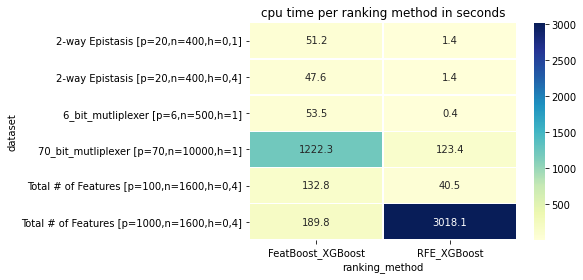

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

ft = rankdata[rankdata['dataset'].isin(datasets)]
rectangular = pd.pivot_table(ft, values='cpu_time', index=['dataset'], columns=['ranking_method'])
g = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu")
plt.title('cpu time per ranking method in seconds')

Timings for ALL datasets.

Text(0.5, 1.0, 'cpu time per ranking method in seconds')

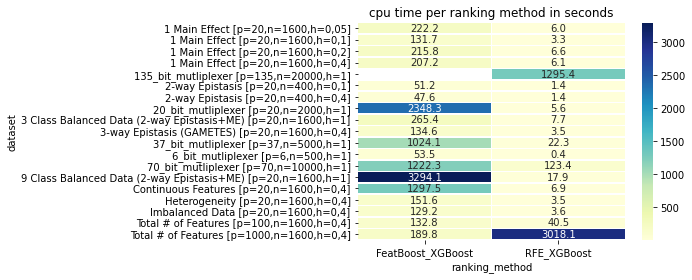

In [5]:
rectangular = pd.pivot_table(rankdata, values='cpu_time', index=['dataset'], columns=['ranking_method'])
g = sns.heatmap(rectangular, annot=True, fmt=".1f", linewidths=.5, cmap="YlGnBu")
plt.title('cpu time per ranking method in seconds')

In [4]:
# sns.catplot(x="dataset_no", y="cpu_time", hue="ranking_method", 
#             data=all_results, col="dataset", col_wrap=4, kind="bar", 
#             facet_kws={'sharey': False})

## Validation results
Validation using KNN.

In [9]:
if not os.path.exists('valdata.csv'): # one-time results collection operation
    valdata = pd.DataFrame()
    for dataset in pd.read_csv('./rebate-datasets.csv').itertuples():
        val_path = os.path.join('../../results/old_20200514-1153//validation', dataset.path + '.csv')
        if os.path.exists(val_path):
            data = pd.read_csv(val_path)
            dataset_id = '{} [p={},n={},h={}]'.format(dataset.theme, dataset.p, dataset.n, dataset.heritability)
            data['dataset'] = dataset_id
            valdata = valdata.append(data)
    valdata.to_csv('valdata.csv', index=False)
valdata = pd.read_csv('valdata.csv')

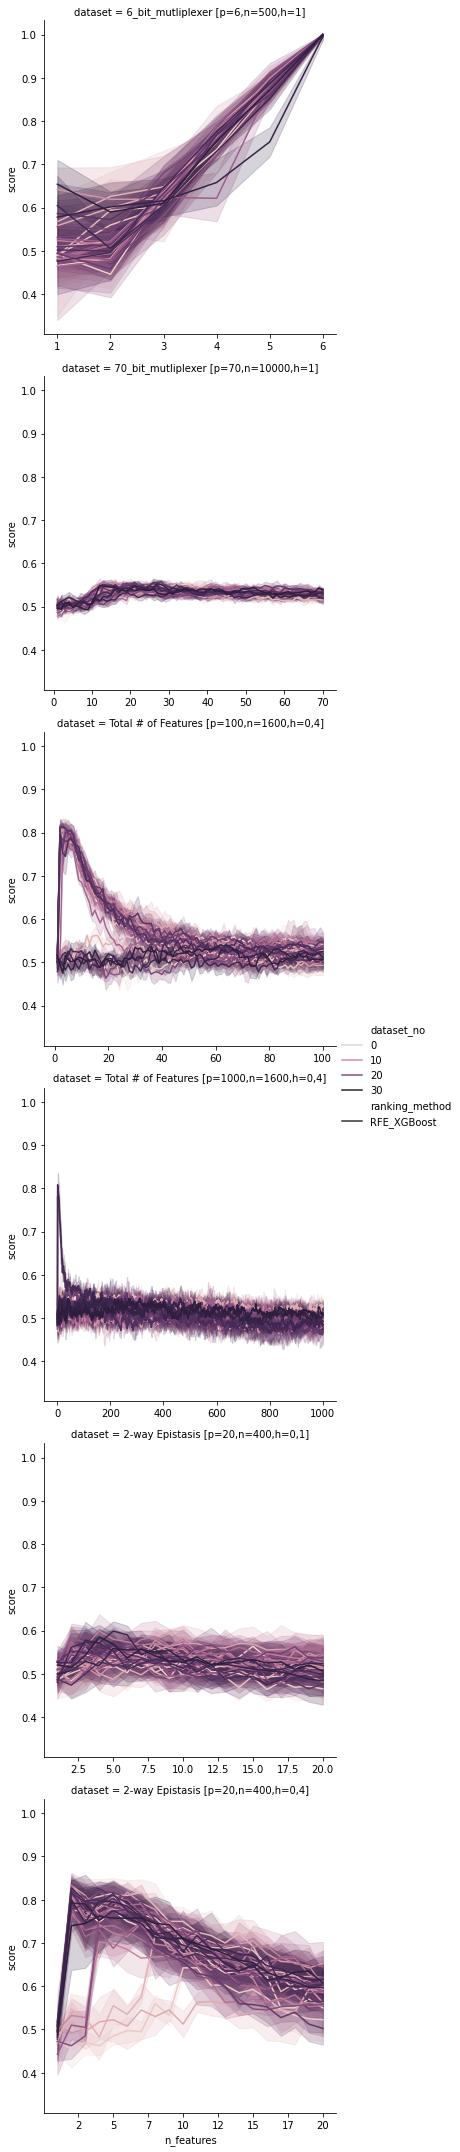

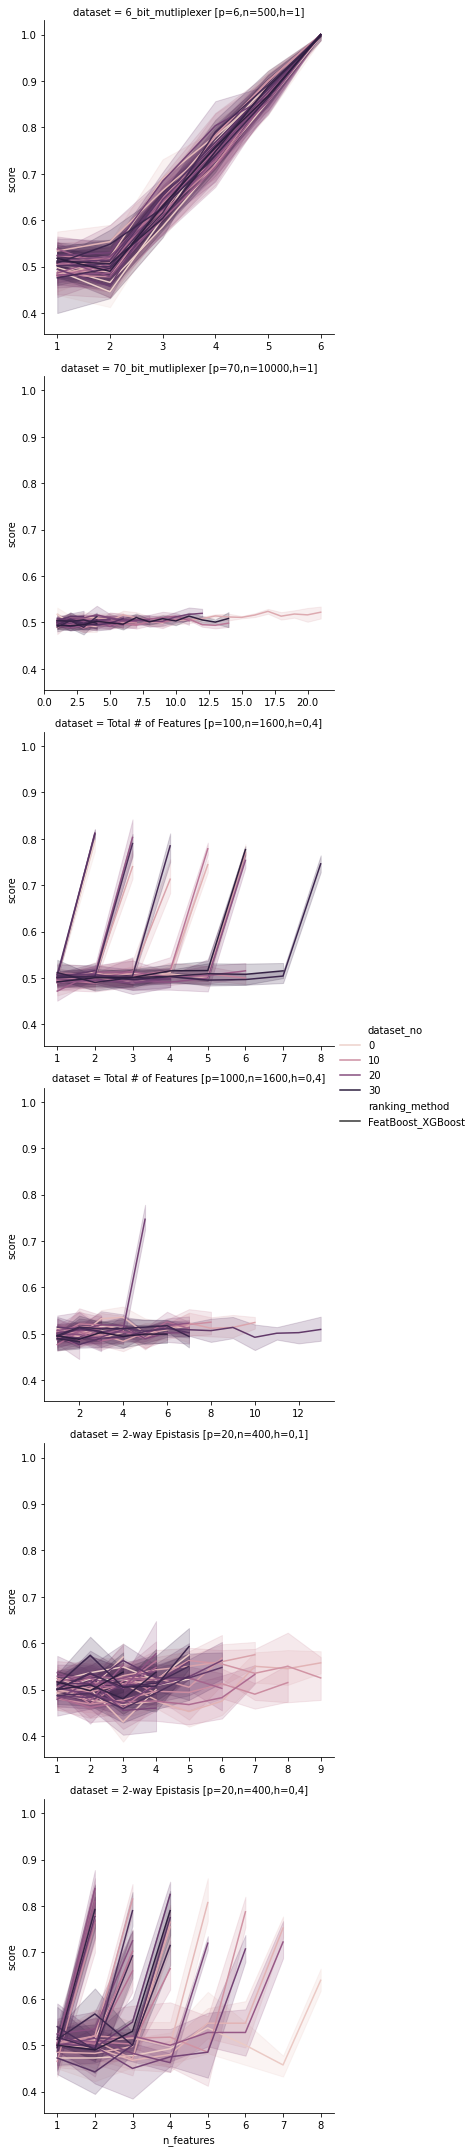

In [39]:
ft = valdata[valdata['ranking_method'] == 'RFE_XGBoost']
ft = ft[ft['dataset'].isin(datasets)]
g = sns.relplot(x="n_features", y="score",
            col="dataset", hue="dataset_no",
            style="ranking_method",
            kind="line",
            col_wrap=1,
            facet_kws={'sharex': False},
            data=ft)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: int(x)))

ft2 = valdata[valdata['ranking_method'] == 'FeatBoost_XGBoost']
ft2 = ft2[ft2['dataset'].isin(datasets)]
g2 = sns.relplot(x="n_features", y="score",
            col="dataset", hue="dataset_no",
            style="ranking_method",
            kind="line",
            col_wrap=1,
            facet_kws={'sharex': False},
            data=ft2)

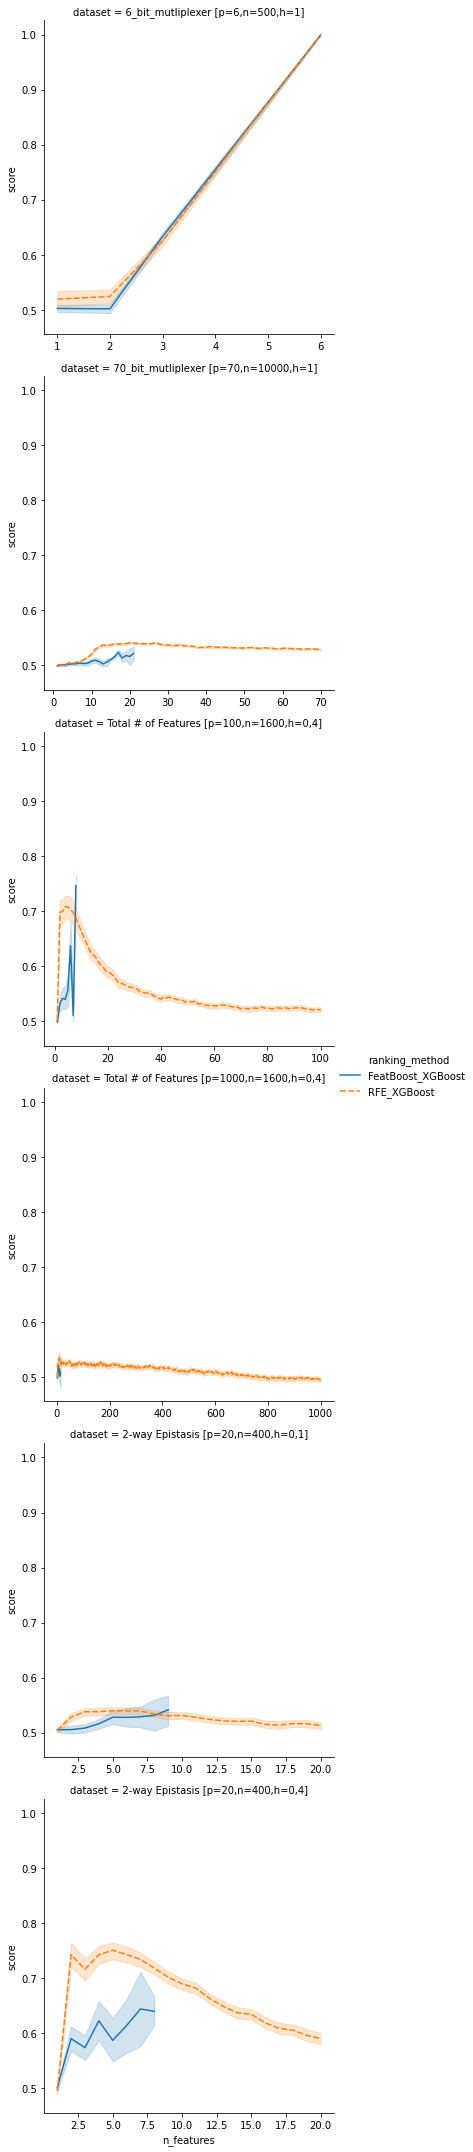

In [40]:
ft_both = valdata[valdata['dataset'].isin(datasets)]
g_both = sns.relplot(x="n_features", y="score",
            col="dataset", hue="ranking_method",
            style="ranking_method",
            kind="line",
            col_wrap=1,
            facet_kws={'sharex': False},
            data=ft_both)

All validation results in 1 plot.

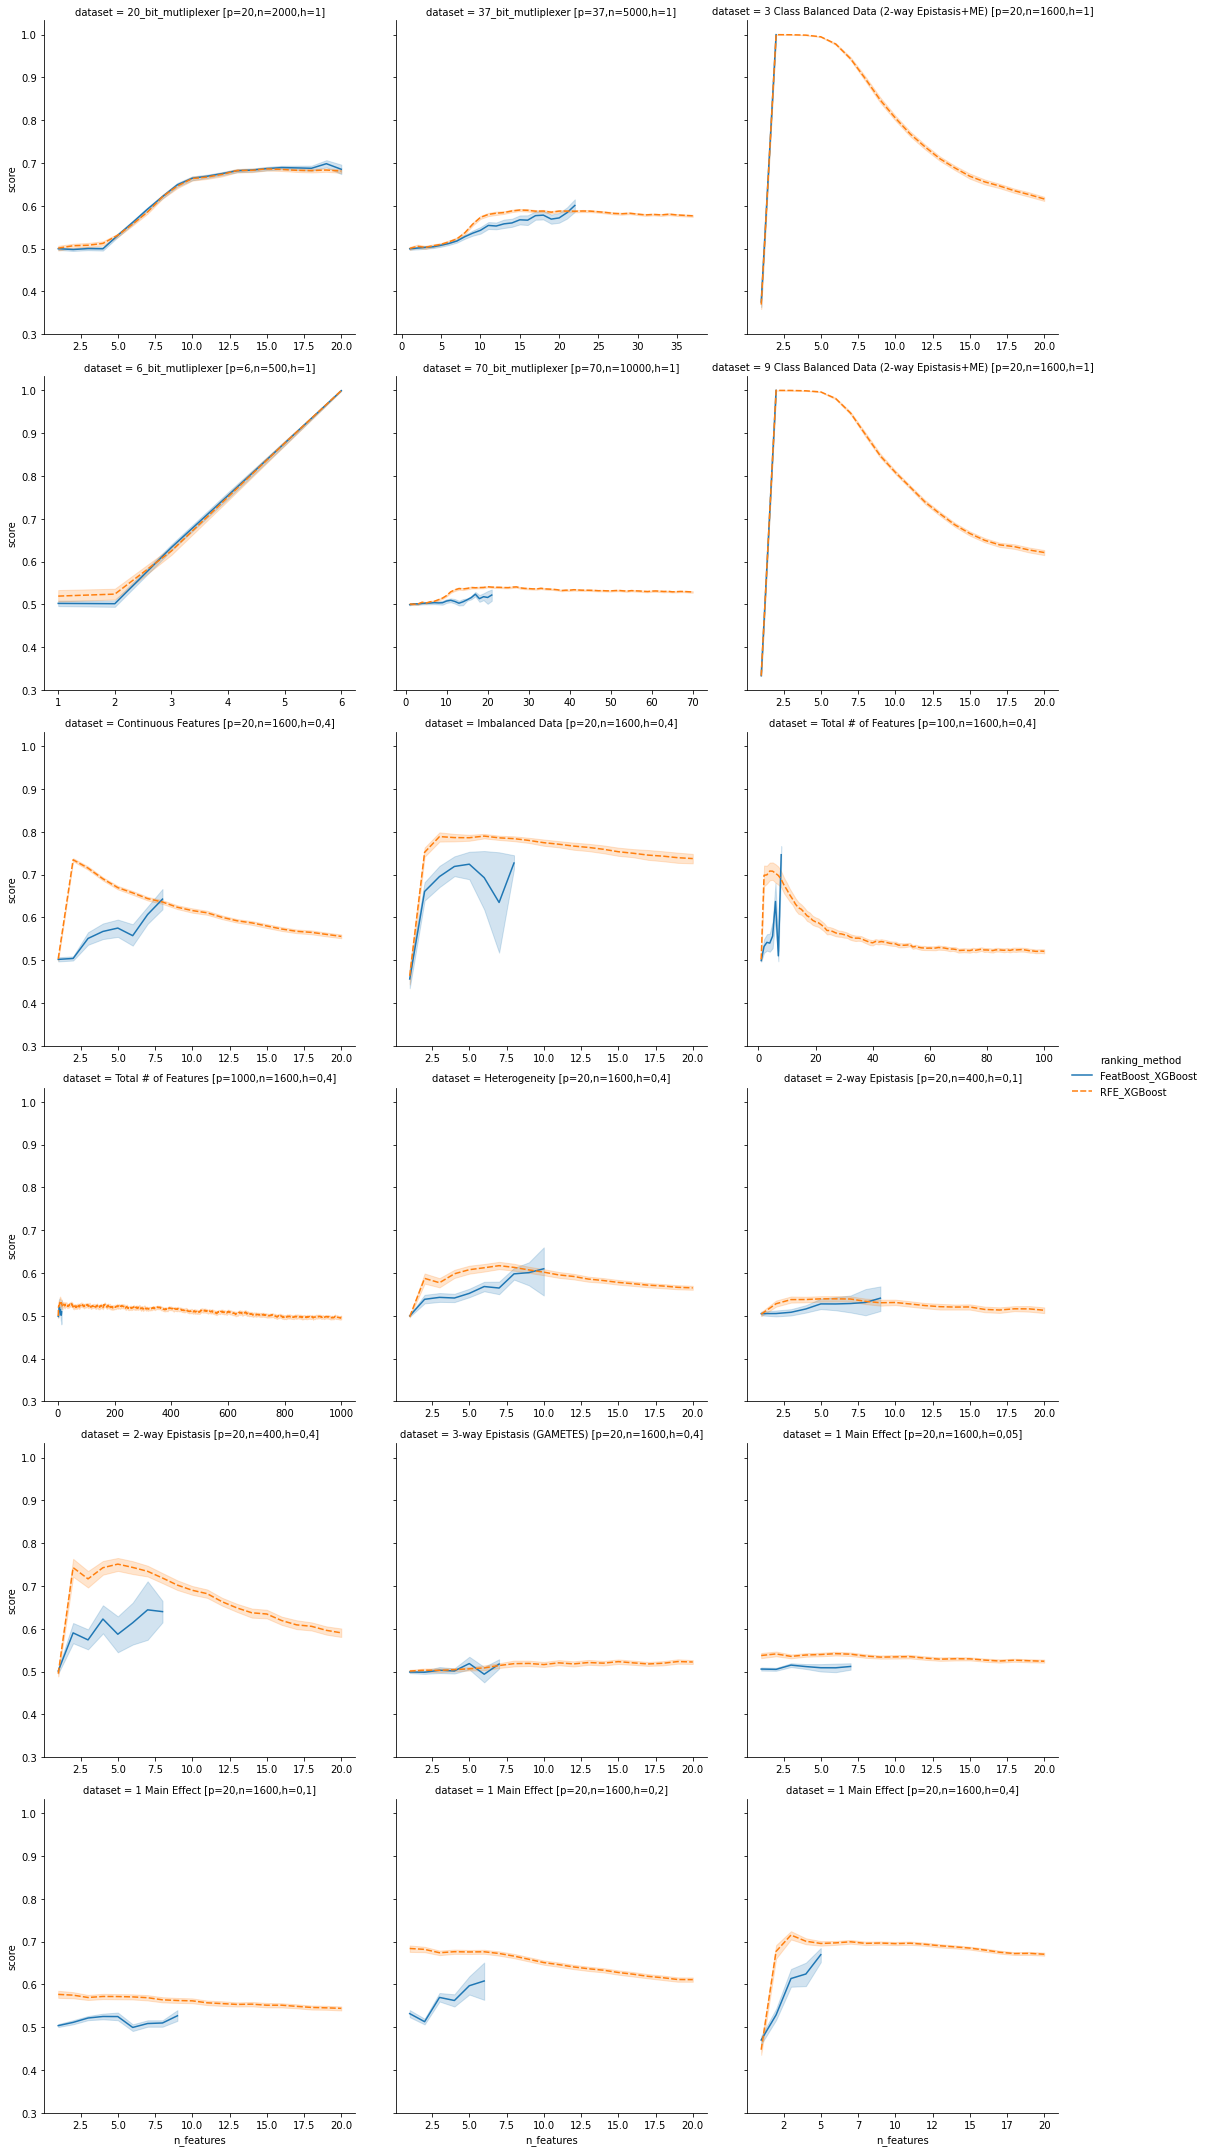

In [46]:
g = sns.relplot(x="n_features", y="score",
            col="dataset", hue="ranking_method",
            style="ranking_method", kind="line",
            col_wrap=3,
            facet_kws={'sharex': False},
            data=valdata)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: int(x)))
g.savefig('validation-results.png')

Removing "skewed" results

valdata size before 190340
valdata size after 188860


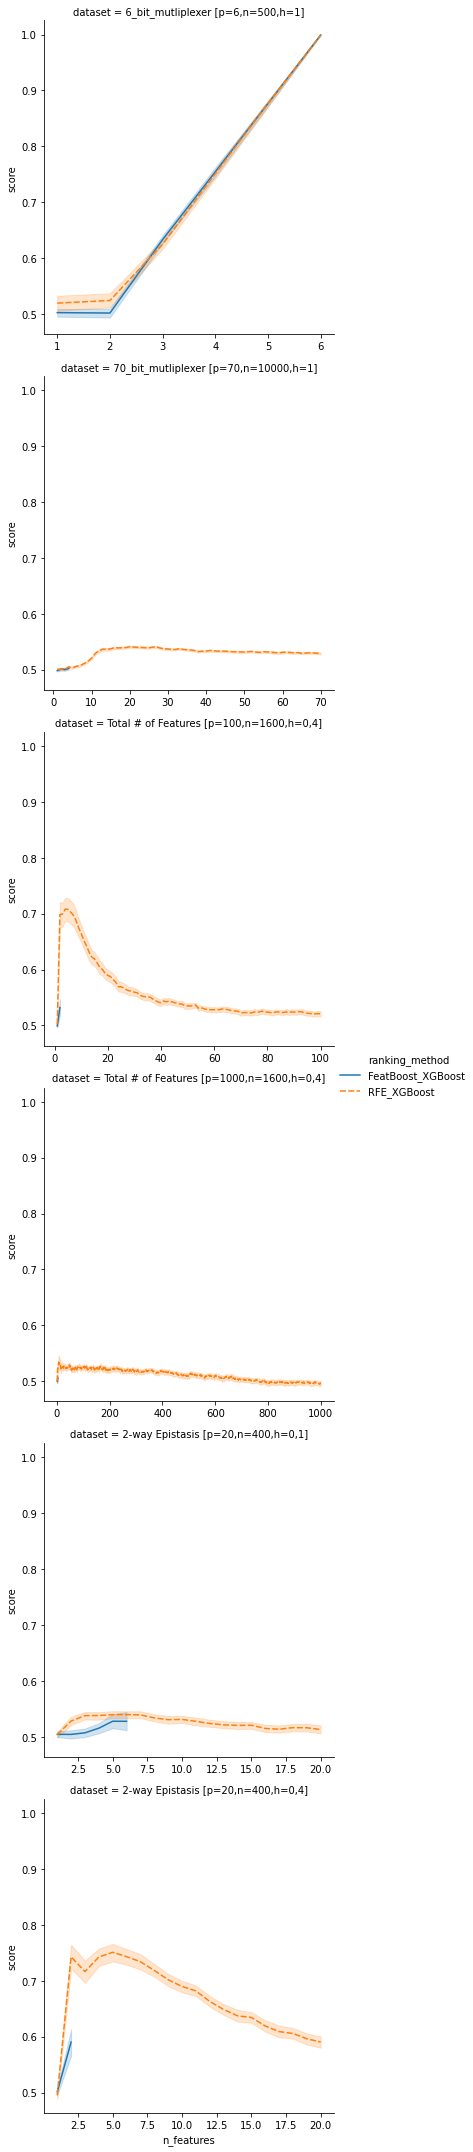

In [52]:
from scipy import stats
rankdata_subset = rankdata[rankdata['dataset'].isin(datasets)]
valdata_subset = valdata[valdata['dataset'].isin(datasets)].reset_index()

### Removing skewed results ###
print('valdata size before', len(valdata_subset.index))
for dataset, dataset_data in rankdata_subset.groupby('dataset'):
    # print(dataset)
    for ranking_method, ranking_method_data in dataset_data.groupby('ranking_method'):
        # print('\t', ranking_method)
        subset_lens = []
        for dataset_no, subset in ranking_method_data.groupby('dataset_no'):
            subset_lens.append(len(subset.index))
            # print(len(subset.index))
        mode = stats.mode(subset_lens).mode[0]
        # print('\t', mode)

        for dataset_no, subset in ranking_method_data.groupby('dataset_no'):
            # drop replica
            # print('dataset_no', dataset_no)
            subset_len = len(subset.index)
            if subset_len < mode:
                # print('\t\tdrop', dataset_no, ', subset_len =', subset_len)
                to_drop = valdata_subset[\
                    (valdata_subset['dataset'] == dataset) & \
                    (valdata_subset['ranking_method'] == ranking_method) & \
                    (valdata_subset['dataset_no'] == dataset_no)
                    ]
                # print('before', len(valdata_subset.index))
                # print('dropping', len(to_drop.index))
                # print(to_drop)
                valdata_subset = valdata_subset.drop(to_drop.index)
                # print('after', len(valdata_subset.index))
            # if subset_len == mode:
                # print('\t\tequal', dataset_no, ', subset_len =', subset_len)
            if subset_len > mode:
                # print('\t\ttruncate', dataset_no, ', subset_len =', subset_len)
                to_truncate = valdata_subset[\
                    (valdata_subset['dataset'] == dataset) & \
                    (valdata_subset['ranking_method'] == ranking_method) & \
                    (valdata_subset['dataset_no'] == dataset_no) &\
                    (valdata_subset['n_features'] > mode)
                    ]
                # print('before', len(valdata_subset.index))
                # print('dropping', len(to_truncate.index))
                # print(to_truncate)
                valdata_subset = valdata_subset.drop(to_truncate.index)
                # print('after', len(valdata_subset.index))
                # break

print('valdata size after', len(valdata_subset.index))
g_both = sns.relplot(x="n_features", y="score",
            col="dataset", hue="ranking_method",
            style="ranking_method",
            kind="line",
            col_wrap=1,
            facet_kws={'sharex': False},
            data=valdata_subset)